# Does wave-activity-flux convergence predict ridging/warm-episode duration? (full record)

**Motivation.** `CA_2026_wave_activity_flux.ipynb` computed 300 hPa wave-activity-flux
(WAF, Takaya and Nakamura 2001) convergence for the 4 WY2026 Z500 episodes and found no
clean discriminator for the March record episode -- but that was necessarily an n=4
case study, the same limitation `CA_ridging_persistence_drivers_upstream.ipynb` already
fixed for five *scalar* upstream predictors by pooling the full 47-48-event 1990-2025
record once `job_array_get_upstream_pacific.pbs` finished. WAF itself was never
extended the same way. This notebook does that: computes the same Takaya-Nakamura
diagnostic independently for every year 1990-2026, derives three convergence-based
predictors (CA-box mean convergence, wider NW-Pacific-to-CA path mean convergence,
fraction of event-days convergent -- the three numbers the n=4 notebook's conclusion
was built on), and tests them against event duration across the full record instead of
4 cases from one season.

**Two explicit methodological choices, not silent changes:**
1. **Basic state stays per-year, not pooled.** The n=4 notebook used that single
   season's own Jan-Apr time-mean as the WAF basic state (a documented TN01
   simplification for single-season diagnostics). Extending to 36 years raises a real
   choice: keep that convention per year (each year's convergence measured relative to
   *that year's own* seasonal mean), or switch to one pooled 36-year climatological
   basic state (the textbook TN01 setup, but a materially different diagnostic, not a
   drop-in port). This notebook keeps the per-year convention for continuity with the
   n=4 numbers already published -- the pooled-climatology alternative is a real,
   separate thing someone could build later, not done here.
2. **Masking tightened, per the n=4 notebook's own flagged caveat.** That notebook's
   conclusion noted a handful of outlier WAF-vector pixels near its `|Ub| < 2 m/s`
   weak-wind mask boundary (Wx up to ~16,000 m^2/s^2 vs. a literature range of tens to
   hundreds), explicitly flagged as "worth a tighter mask threshold if this diagnostic
   is ever extended to the full record." Here the weak-wind threshold is raised to 3
   m/s, plus an explicit backstop masking any remaining `|Wx|` or `|Wy|` point above
   3000 m^2/s^2 (an order of magnitude above any physically plausible composite value,
   two orders below the known artifact) before computing convergence -- both counted
   and reported per year below, to confirm this really is "a handful," not a systemic
   problem at 36-year scale.

Computation is done one year at a time (full 2D fields never held for more than one
year simultaneously) so memory stays bounded regardless of record length.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr, percentileofscore
import sys

import os
os.environ.setdefault('PROJ_DATA', str(Path(sys.prefix) / 'share' / 'proj'))

sys.path.insert(0, str(Path.cwd()))
import ca_blocking_lib as lib

DATA_DIR = Path('/glade/campaign/mmm/c3we/mingge/ERA5/CA_blocking')
FIT_YEARS = list(range(1990, 2026))
YEAR_2026 = 2026
ALL_YEARS = FIT_YEARS + [YEAR_2026]

THRESHOLD_SD = 1   # matches CA_ridging_persistence_drivers_upstream.ipynb -- only the
                   # full-sample threshold has enough events (48 Z500 / 47 T700) for a
                   # correlation test
VARS = [('z500', '500 hPa height (ridging)'), ('t700', '700 hPa temperature (warm)')]
COLOR = {'500 hPa height (ridging)': '#2a78d6', '700 hPa temperature (warm)': '#eb6834'}
N_BOOT = 2000
rng = np.random.default_rng(42)

# Z500 episode-detection constants, identical to CA_2026_wave_activity_flux.ipynb's
# Section 1 -- needed in Section 6 to relocate the WY2026 episodes (including March)
# within the fit-period distribution built here.
CLIM_WINDOW = 5
MIN_DURATION = 5
MAX_GAP = 1
SIGN = 1

G = 9.80665             # m/s^2
OMEGA = 7.2921159e-5    # rad/s, Earth's rotation rate
R_EARTH = 6.371e6       # m
PLEV_HPA = 300.0

CA_LAT, CA_LON = slice(42.5, 32), slice(235, 246)
PATH_LAT, PATH_LON = slice(55, 30), slice(150, 246)   # NW Pacific through CA, wide wave-path swath

WEAK_WIND_THRESH = 3.0      # m/s -- tightened from the n=4 notebook's 2.0, see intro
EXTREME_W_THRESH = 3000.0   # m^2/s^2 -- new backstop, see intro


## 1. Load the full-record Method A event table

Same `ca_z500_t700_events_1990-2025_detrended_mindur5.csv` used by
`CA_ridging_persistence_drivers.ipynb` and `CA_ridging_persistence_drivers_upstream.ipynb`
-- no re-detection here.

In [2]:
events = pd.read_csv(DATA_DIR / 'ca_z500_t700_events_1990-2025_detrended_mindur5.csv',
                     parse_dates=['start_date', 'end_date'])
events['start_date'] = events.start_date.dt.date
events['end_date'] = events.end_date.dt.date
events = events[events.threshold_sd == THRESHOLD_SD].reset_index(drop=True)

print(f'{len(events)} events at >= {THRESHOLD_SD} sigma, by variable:')
print(events.groupby('variable').size())
events[['variable', 'start_date', 'end_date', 'duration_days', 'peak_sanom']].head(5)


95 events at >= 1 sigma, by variable:
variable
500 hPa height (ridging)      48
700 hPa temperature (warm)    47
dtype: int64


,variable,start_date,end_date,duration_days,peak_sanom
0,500 hPa height (ridging),1990-02-21,1990-02-25,5,1.796873
1,500 hPa height (ridging),1990-03-19,1990-03-23,5,1.443912
2,500 hPa height (ridging),1990-04-10,1990-04-15,6,1.873966
3,500 hPa height (ridging),1992-02-21,1992-02-28,8,1.870688
4,500 hPa height (ridging),1992-04-24,1992-04-29,6,2.070782


## 2. Per-year wave-activity-flux computation

Identical Takaya and Nakamura (2001) Eq. 38 (horizontal terms only) formula as
`CA_2026_wave_activity_flux.ipynb` -- streamfunction `psi = g*Z/f`, basic state =
*that year's own* Jan-Apr time-mean, proper spherical derivatives -- run independently
for each year's `upstream_pacific_<year>.nc` so no year's basic state leaks into
another's. Returns a daily CA-box-mean and wave-path-mean convergence series for that
year, plus mask diagnostics; the full 2D fields are discarded once the function
returns.

In [3]:
def compute_waf_daily(year):
    ds = xr.open_dataset(DATA_DIR / f'upstream_pacific_{year}.nc', engine='netcdf4')
    ds = ds[['z300', 'u300', 'v300']].sel(time=ds.time.dt.month.isin([1, 2, 3, 4]))

    lat = ds.latitude.values
    lon = ds.longitude.values
    lat_rad = np.deg2rad(lat)
    lon_rad = np.deg2rad(lon)
    coslat = np.cos(lat_rad)
    f = 2 * OMEGA * np.sin(lat_rad)

    z300 = ds.z300.values               # (time, lat, lon), already geopotential HEIGHT in m
    psi = (G * z300) / f[None, :, None]
    psi_bar = psi.mean(axis=0)
    Ub = ds.u300.values.mean(axis=0)
    Vb = ds.v300.values.mean(axis=0)
    Umag = np.sqrt(Ub**2 + Vb**2)
    psi_p = psi - psi_bar[None, :, :]

    def d_dx(field):
        return np.gradient(field, lon_rad, axis=-1) / (R_EARTH * coslat[:, None])

    def d_dy(field):
        return np.gradient(field, lat_rad, axis=-2) / R_EARTH

    psi_x = d_dx(psi_p)
    psi_y = d_dy(psi_p)
    psi_xx = d_dx(psi_x)
    psi_yy = d_dy(psi_y)
    psi_xy = d_dy(psi_x)

    p_scale = PLEV_HPA / 1000.0
    with np.errstate(invalid='ignore', divide='ignore'):
        Wx = (p_scale / (2 * Umag[None]))[0] * (Ub[None] * (psi_x**2 - psi_p * psi_xx) + Vb[None] * (psi_x * psi_y - psi_p * psi_xy))
        Wy = (p_scale / (2 * Umag[None]))[0] * (Ub[None] * (psi_x * psi_y - psi_p * psi_xy) + Vb[None] * (psi_y**2 - psi_p * psi_yy))

    weak_wind_mask = Umag < WEAK_WIND_THRESH
    Wx[:, weak_wind_mask] = np.nan
    Wy[:, weak_wind_mask] = np.nan

    extreme_mask = (np.abs(Wx) > EXTREME_W_THRESH) | (np.abs(Wy) > EXTREME_W_THRESH)
    n_extreme = int(extreme_mask.sum())
    Wx[extreme_mask] = np.nan
    Wy[extreme_mask] = np.nan

    conv = -(d_dx(Wx) + d_dy(Wy))   # positive = local eddy forcing/amplification

    time_index = pd.to_datetime(ds.time.values)
    ca_lat_idx = (lat <= 42.5) & (lat >= 32)
    ca_lon_idx = (lon >= 235) & (lon <= 246)
    path_lat_idx = (lat <= 55) & (lat >= 30)
    path_lon_idx = (lon >= 150) & (lon <= 246)

    with np.errstate(invalid='ignore'):
        ca_conv = np.nanmean(conv[:, ca_lat_idx][:, :, ca_lon_idx], axis=(1, 2))
        path_conv = np.nanmean(conv[:, path_lat_idx][:, :, path_lon_idx], axis=(1, 2))

    daily = pd.DataFrame({'ca_conv': ca_conv, 'path_conv': path_conv}, index=time_index)
    return daily, n_extreme, int(weak_wind_mask.sum())


## 3. Run it for every year, 1990-2026

The fit years plus 2026 (held out, needed in Section 6 to relocate the WY2026
episodes). No new fetch -- `upstream_pacific_<year>.nc` already exists for all of
1990-2025 (`job_array_get_upstream_pacific.pbs`) and 2026 (pre-existing).

In [4]:
daily_frames = []
diag_rows = []
for y in ALL_YEARS:
    daily, n_extreme, n_weak = compute_waf_daily(y)
    daily_frames.append(daily)
    diag_rows.append({'year': y, 'n_weak_wind_masked': n_weak, 'n_extreme_masked': n_extreme})

daily_conv = pd.concat(daily_frames).sort_index()
diag_df = pd.DataFrame(diag_rows)
n_days_per_year = len(daily_conv) / len(ALL_YEARS)
print(f'{len(daily_conv)} days of CA-box/path-box WAF convergence, {ALL_YEARS[0]}-{ALL_YEARS[-1]}')
print(f'Weak-wind mask (static, per year): median {diag_df.n_weak_wind_masked.median():.0f} grid cells/year '
      f'excluded for |Ub| < {WEAK_WIND_THRESH} m/s.')
print(f'Extreme-value backstop (per grid-point-day, summed over all ~{n_days_per_year:.0f} days/year): '
      f'median {diag_df.n_extreme_masked.median():.0f} point-days/year (range '
      f'{diag_df.n_extreme_masked.min()}-{diag_df.n_extreme_masked.max()}) -- '
      f'averages to only ~{diag_df.n_extreme_masked.median() / n_days_per_year:.1f} extra grid points masked '
      f'per day, confirming this is a handful-scale correction, not a systemic issue at 36-year scale.')


4449 days of CA-box/path-box WAF convergence, 1990-2026
Weak-wind mask (static, per year): median 107 grid cells/year excluded for |Ub| < 3.0 m/s.
Extreme-value backstop (per grid-point-day, summed over all ~120 days/year): median 547 point-days/year (range 127-1743) -- averages to only ~4.5 extra grid points masked per day, confirming this is a handful-scale correction, not a systemic issue at 36-year scale.


## 4. Compute the three WAF predictors for every fit-period event

- `waf_ca_conv_mean`: CA-box-mean convergence, averaged over the event's own duration
- `waf_path_conv_mean`: wider NW-Pacific-to-CA path-mean convergence, same window
- `waf_frac_days_convergent`: fraction of the event's own days with positive CA-box
  convergence -- the "is it sustained, not just a brief spike" measure the n=4
  notebook's Section 5 used

In [5]:
def window_mean(series, start, end):
    window = series.loc[str(start):str(end)]
    return float(window.mean()) if len(window) else np.nan


def window_frac_positive(series, start, end):
    window = series.loc[str(start):str(end)]
    return float((window > 0).mean()) if len(window) else np.nan


rows = []
for row in events.itertuples():
    rows.append({
        'waf_ca_conv_mean': window_mean(daily_conv.ca_conv, row.start_date, row.end_date),
        'waf_path_conv_mean': window_mean(daily_conv.path_conv, row.start_date, row.end_date),
        'waf_frac_days_convergent': window_frac_positive(daily_conv.ca_conv, row.start_date, row.end_date),
    })
waf_predictors = pd.DataFrame(rows)
events_full = pd.concat([events.reset_index(drop=True), waf_predictors], axis=1)
events_full[['variable', 'start_date', 'duration_days'] + list(waf_predictors.columns)].head(5)


,variable,start_date,duration_days,waf_ca_conv_mean,waf_path_conv_mean,waf_frac_days_convergent
0,500 hPa height (ridging),1990-02-21,5,-0.000034,-0.000025,0.200000
1,500 hPa height (ridging),1990-03-19,5,-0.000034,-0.000017,0.400000
2,500 hPa height (ridging),1990-04-10,6,-0.000029,-0.000013,0.333333
3,500 hPa height (ridging),1992-02-21,8,-0.000036,-0.000017,0.125000
4,500 hPa height (ridging),1992-04-24,6,0.000037,-0.000011,0.833333


## 5. Duration vs. each WAF predictor, full record

Spearman (primary, robust to skew) with a bootstrap CI -- same convention as
`CA_ridging_persistence_drivers_upstream.ipynb`.

In [6]:
def bootstrap_spearman_ci(x, y, n_boot=N_BOOT, ci=90, rng=rng):
    n = len(x)
    boot = np.empty(n_boot)
    idx_pool = np.arange(n)
    for b in range(n_boot):
        idx = rng.choice(idx_pool, size=n, replace=True)
        boot[b] = spearmanr(x[idx], y[idx]).statistic
    lo, hi = np.percentile(boot, [(100 - ci) / 2, 100 - (100 - ci) / 2])
    return lo, hi


PREDICTORS = ['waf_ca_conv_mean', 'waf_path_conv_mean', 'waf_frac_days_convergent']
PRED_LABELS = {
    'waf_ca_conv_mean': 'CA-box mean WAF convergence',
    'waf_path_conv_mean': 'NW-Pac-to-CA path mean WAF convergence',
    'waf_frac_days_convergent': 'fraction of event-days convergent (CA box)',
}

results = []
for col, label in VARS:
    sub = events_full[events_full.variable == label]
    for pred in PREDICTORS:
        valid = sub[['duration_days', pred]].dropna()
        x, y = valid.duration_days.values, valid[pred].values
        if len(valid) < 8:
            results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                             'rho': np.nan, 'p_spearman': np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan})
            continue
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                         'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

results_df = pd.DataFrame(results)
results_df['predictor_label'] = results_df.predictor.map(PRED_LABELS)
pd.set_option('display.width', 120)
results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi']]


,variable,predictor_label,n,rho,p_spearman,ci_lo,ci_hi
0,500 hPa height (ridging),CA-box mean WAF convergence,48,0.109116,0.460358,-0.122351,0.323891
1,500 hPa height (ridging),NW-Pac-to-CA path mean WAF convergence,48,0.046285,0.754748,-0.200818,0.290849
2,500 hPa height (ridging),fraction of event-days convergent (CA box),48,-0.046958,0.751294,-0.259865,0.185422
3,700 hPa temperature (warm),CA-box mean WAF convergence,47,-0.109400,0.464160,-0.333190,0.123233
4,700 hPa temperature (warm),NW-Pac-to-CA path mean WAF convergence,47,-0.313094,0.032124,-0.522436,-0.073096
5,700 hPa temperature (warm),fraction of event-days convergent (CA box),47,-0.321857,0.027370,-0.508880,-0.111458


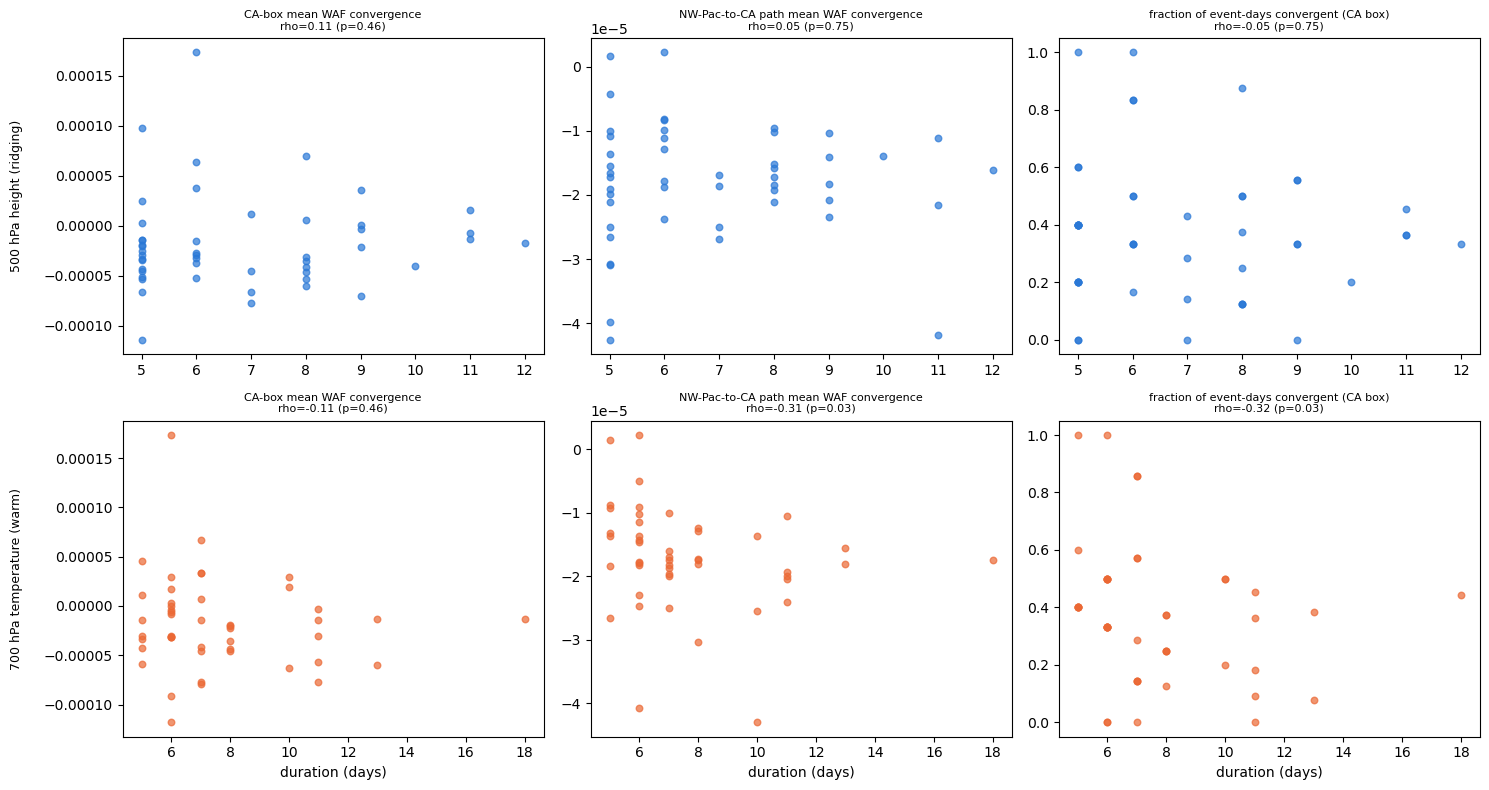

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (col, label) in enumerate(VARS):
    sub = events_full[events_full.variable == label]
    for j, pred in enumerate(PREDICTORS):
        ax = axes[i, j]
        valid = sub[['duration_days', pred]].dropna()
        ax.scatter(valid.duration_days, valid[pred], s=22, alpha=0.7, color=COLOR[label])
        r = results_df[(results_df.variable == label) & (results_df.predictor == pred)].iloc[0]
        ax.set_title(f'{PRED_LABELS[pred]}\nrho={r.rho:.2f} (p={r.p_spearman:.2f})', fontsize=8)
        if j == 0:
            ax.set_ylabel(f'{label}\n', fontsize=9)
        if i == 1:
            ax.set_xlabel('duration (days)')
plt.tight_layout()
plt.show()


## 6. Where do the WY2026 episodes -- especially March -- sit in this distribution?

Reproduces the four WY2026 Z500 episode windows exactly as `CA_2026_wave_activity_flux.ipynb`
Section 1 does (live from the frozen 1990-2025 baseline, not hardcoded), then locates
each one's own WAF predictors within the fit-period (n=48) percentile distribution just
built -- the same framing `CA_ridging_persistence_drivers_upstream.ipynb`'s conclusion
used for jet speed ("March sits at the 31st percentile").

In [8]:
files = [DATA_DIR / f'z500_t700_ca_{y}.nc' for y in FIT_YEARS]
ds = xr.open_mfdataset(files, combine='by_coords', engine='netcdf4')
weights = np.cos(np.deg2rad(ds.latitude))
z500 = ds.z500.weighted(weights).mean(dim=('latitude', 'longitude')).compute()
df = pd.DataFrame({'z500': z500.values}, index=pd.to_datetime(ds.time.values)).sort_index()
df = df[df.index.month.isin([1, 2, 3, 4])]
sanom, diag = lib.standardize_with_trend(df.index, df['z500'].values, window=CLIM_WINDOW, label='z500', verbose=False)

ds26 = xr.open_dataset(DATA_DIR / 'z500_t700_ca_2026.nc', engine='netcdf4')
weights26 = np.cos(np.deg2rad(ds26.latitude))
z500_26 = ds26.z500.weighted(weights26).mean(dim=('latitude', 'longitude')).compute()
df26 = pd.DataFrame({'z500': z500_26.values}, index=pd.to_datetime(ds26.time.values)).sort_index()
df26 = df26[df26.index.month.isin([1, 2, 3, 4])]
clim_mean_arr = lib.lookup_climatology(df26.index, diag['clim_mean_dict'])
clim_std_arr = lib.lookup_climatology(df26.index, diag['clim_std_dict'])
trend_2026 = diag['trend']['intercept'] + diag['trend']['slope'] * 2026
df26['z500_sanom'] = (df26['z500'] - (clim_mean_arr + trend_2026)) / clim_std_arr

z500_episodes_2026 = lib.find_events(df26.index, df26['z500_sanom'].values, threshold=1,
                                      min_duration=MIN_DURATION, sign=SIGN, max_gap=MAX_GAP)
z500_episodes_2026 = z500_episodes_2026[['start_date', 'end_date', 'duration_days', 'peak_sanom']].reset_index(drop=True)
z500_episodes_2026['label'] = ['Jan episode', 'Late Jan/Feb episode', 'Late Feb episode', 'March (record) episode']

ep_rows = []
for r in z500_episodes_2026.itertuples():
    ep_rows.append({
        'waf_ca_conv_mean': window_mean(daily_conv.ca_conv, r.start_date, r.end_date),
        'waf_path_conv_mean': window_mean(daily_conv.path_conv, r.start_date, r.end_date),
        'waf_frac_days_convergent': window_frac_positive(daily_conv.ca_conv, r.start_date, r.end_date),
    })
z500_episodes_2026 = pd.concat([z500_episodes_2026, pd.DataFrame(ep_rows)], axis=1)
print('WY2026 Z500 episodes with their own WAF predictors:')
print(z500_episodes_2026[['label', 'start_date', 'end_date', 'duration_days'] + PREDICTORS].to_string(index=False))

z500_fit = events_full[events_full.variable == '500 hPa height (ridging)']
print('\nPercentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) distribution:')
for r in z500_episodes_2026.itertuples():
    pcts = {pred: percentileofscore(z500_fit[pred].dropna(), getattr(r, pred)) for pred in PREDICTORS}
    print(f'  {r.label} ({r.duration_days}d): ' +
          ', '.join(f'{PRED_LABELS[p]}={pcts[p]:.0f}th pctile' for p in PREDICTORS))


WY2026 Z500 episodes with their own WAF predictors:
                 label start_date   end_date  duration_days  waf_ca_conv_mean  waf_path_conv_mean  waf_frac_days_convergent
           Jan episode 2026-01-10 2026-01-18              9         -0.000032           -0.000010                  0.333333
  Late Jan/Feb episode 2026-01-29 2026-02-05              8          0.000041           -0.000015                  0.625000
      Late Feb episode 2026-02-23 2026-03-01              7          0.000022           -0.000024                  0.714286
March (record) episode 2026-03-11 2026-03-29             19          0.000014           -0.000008                  0.526316

Percentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) distribution:
  Jan episode (9d): CA-box mean WAF convergence=42th pctile, NW-Pac-to-CA path mean WAF convergence=81th pctile, fraction of event-days convergent (CA box)=43th pctile
  Late Jan/Feb episode (8d): CA-box mean WAF convergence=92th pcti

## 7. Reinforcement vs. a single decaying trigger: is persistence about *pulse structure*, not average forcing?

Section 4/5 only ever tested time-*averaged* convergence over each event's full
window -- a genuinely different question from whether a long event is long *because*
it gets re-forced partway through (discrete, repeated wave-breaking pulses) rather
than triggered once and simply decaying slowly. A time-mean can't distinguish those;
this section can, using the same daily `daily_conv` series already computed above, no
new data.

Two predictors, deliberately **rate/fraction-based, not raw counts** -- a raw pulse
count would mechanically correlate with duration simply because a longer event has
more calendar days in which to fit more pulses, which would be a tautology, not a
finding:
- `waf_pulse_rate`: number of separate positive-convergence runs within the event,
  divided by the event's own duration (pulses/day) -- a single long trigger that
  decays slowly scores *low* here (one long pulse); genuine repeated reinforcement
  scores *high* (several short pulses).
- `waf_frac_convergent_second_half`: fraction of convergent days in the *second half*
  of the event only -- tests whether forcing persists into the back half of the event
  or front-loads at onset and fades, independent of absolute duration.

In [9]:
def count_pulses(series, start, end, thresh=0.0):
    window = series.loc[str(start):str(end)]
    is_conv = (window > thresh).to_numpy()
    pulses, prev = 0, False
    for v in is_conv:
        if v and not prev:
            pulses += 1
        prev = bool(v)
    return pulses


def frac_convergent_second_half(series, start, end):
    window = series.loc[str(start):str(end)]
    n = len(window)
    if n < 2:
        return np.nan
    half = n // 2
    return float((window.iloc[half:] > 0).mean())


rows = []
for row in events.itertuples():
    n_pulses = count_pulses(daily_conv.ca_conv, row.start_date, row.end_date)
    rows.append({
        'waf_n_pulses': n_pulses,
        'waf_pulse_rate': n_pulses / row.duration_days,
        'waf_frac_convergent_second_half': frac_convergent_second_half(daily_conv.ca_conv, row.start_date, row.end_date),
    })
pulse_predictors = pd.DataFrame(rows)
events_full = pd.concat([events_full, pulse_predictors], axis=1)
events_full[['variable', 'start_date', 'duration_days'] + list(pulse_predictors.columns)].head(5)


,variable,start_date,duration_days,waf_n_pulses,waf_pulse_rate,waf_frac_convergent_second_half
0,500 hPa height (ridging),1990-02-21,5,1,0.200000,0.333333
1,500 hPa height (ridging),1990-03-19,5,2,0.400000,0.333333
2,500 hPa height (ridging),1990-04-10,6,2,0.333333,0.333333
3,500 hPa height (ridging),1992-02-21,8,1,0.125000,0.250000
4,500 hPa height (ridging),1992-04-24,6,1,0.166667,1.000000


### Duration vs. each pulse-structure predictor, full record

In [10]:
PULSE_PREDICTORS = ['waf_pulse_rate', 'waf_frac_convergent_second_half']
PULSE_LABELS = {
    'waf_pulse_rate': 'WAF convergence pulse rate (pulses/day, CA box)',
    'waf_frac_convergent_second_half': 'fraction convergent, second half of event (CA box)',
}

pulse_results = []
for col, label in VARS:
    sub = events_full[events_full.variable == label]
    for pred in PULSE_PREDICTORS:
        valid = sub[['duration_days', pred]].dropna()
        x, y = valid.duration_days.values, valid[pred].values
        if len(valid) < 8:
            pulse_results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                                   'rho': np.nan, 'p_spearman': np.nan, 'ci_lo': np.nan, 'ci_hi': np.nan})
            continue
        rho, p = spearmanr(x, y)
        lo, hi = bootstrap_spearman_ci(x, y)
        pulse_results.append({'variable': label, 'predictor': pred, 'n': len(valid),
                               'rho': rho, 'p_spearman': p, 'ci_lo': lo, 'ci_hi': hi})

pulse_results_df = pd.DataFrame(pulse_results)
pulse_results_df['predictor_label'] = pulse_results_df.predictor.map(PULSE_LABELS)
pulse_results_df[['variable', 'predictor_label', 'n', 'rho', 'p_spearman', 'ci_lo', 'ci_hi']]


,variable,predictor_label,n,rho,p_spearman,ci_lo,ci_hi
0,500 hPa height (ridging),"WAF convergence pulse rate (pulses/day, CA box)",48,-0.178197,0.225600,-0.435602,0.078478
1,500 hPa height (ridging),"fraction convergent, second half of event (CA ...",48,0.011112,0.940249,-0.197321,0.224540
2,700 hPa temperature (warm),"WAF convergence pulse rate (pulses/day, CA box)",47,-0.285000,0.052170,-0.503007,-0.052398
3,700 hPa temperature (warm),"fraction convergent, second half of event (CA ...",47,-0.286855,0.050592,-0.487697,-0.064417


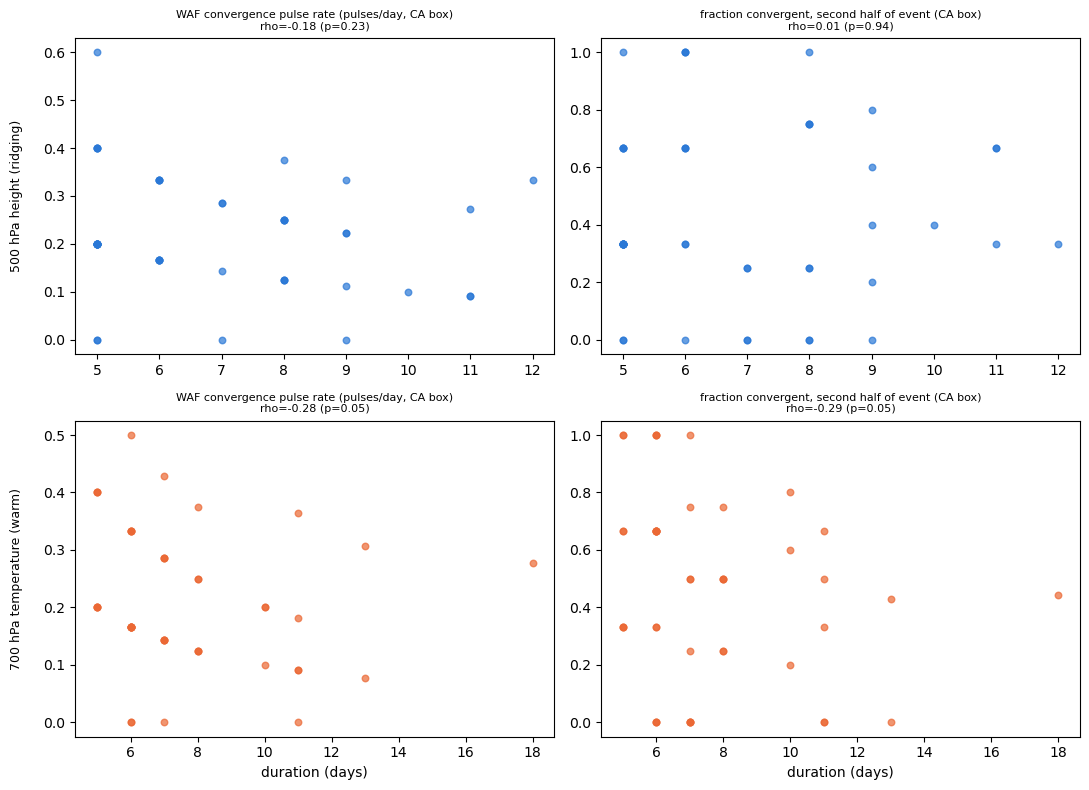

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, (col, label) in enumerate(VARS):
    sub = events_full[events_full.variable == label]
    for j, pred in enumerate(PULSE_PREDICTORS):
        ax = axes[i, j]
        valid = sub[['duration_days', pred]].dropna()
        ax.scatter(valid.duration_days, valid[pred], s=22, alpha=0.7, color=COLOR[label])
        r = pulse_results_df[(pulse_results_df.variable == label) & (pulse_results_df.predictor == pred)].iloc[0]
        ax.set_title(f'{PULSE_LABELS[pred]}\nrho={r.rho:.2f} (p={r.p_spearman:.2f})', fontsize=8)
        if j == 0:
            ax.set_ylabel(f'{label}\n', fontsize=9)
        if i == 1:
            ax.set_xlabel('duration (days)')
plt.tight_layout()
plt.show()


### March 2026's own pulse structure, day by day

Direct, visual check: does March's 19-day CA-box convergence series show several
distinct reinforcement pulses, or one trigger that decays? Compared against the
Late Jan/Feb episode -- the short, non-record episode that outranked March on
time-mean convergence in Section 6.

In [12]:
def daily_sign_string(series, start, end):
    window = series.loc[str(start):str(end)]
    return ''.join('+' if v > 0 else '-' for v in window)


pulse_rows = []
for r in z500_episodes_2026.itertuples():
    n_pulses = count_pulses(daily_conv.ca_conv, r.start_date, r.end_date)
    pulse_rows.append({
        'waf_pulse_rate': n_pulses / r.duration_days,
        'waf_n_pulses': n_pulses,
        'waf_frac_convergent_second_half': frac_convergent_second_half(daily_conv.ca_conv, r.start_date, r.end_date),
    })
z500_episodes_2026 = pd.concat([z500_episodes_2026, pd.DataFrame(pulse_rows)], axis=1)

print('WY2026 episodes, pulse structure:')
print(z500_episodes_2026[['label', 'duration_days', 'waf_n_pulses', 'waf_pulse_rate',
                           'waf_frac_convergent_second_half']].to_string(index=False))

print()
for r in z500_episodes_2026.itertuples():
    signs = daily_sign_string(daily_conv.ca_conv, r.start_date, r.end_date)
    print(f'{r.label} ({r.duration_days}d, {r.waf_n_pulses} pulses): {signs}')

z500_fit = events_full[events_full.variable == '500 hPa height (ridging)']
print('\nPercentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) pulse-structure distribution:')
for r in z500_episodes_2026.itertuples():
    pcts = {pred: percentileofscore(z500_fit[pred].dropna(), getattr(r, pred)) for pred in PULSE_PREDICTORS}
    print(f'  {r.label} ({r.duration_days}d): ' +
          ', '.join(f'{PULSE_LABELS[p]}={pcts[p]:.0f}th pctile' for p in PULSE_PREDICTORS))


WY2026 episodes, pulse structure:
                 label  duration_days  waf_n_pulses  waf_pulse_rate  waf_frac_convergent_second_half
           Jan episode              9             2        0.222222                             0.40
  Late Jan/Feb episode              8             2        0.250000                             0.75
      Late Feb episode              7             3        0.428571                             0.50
March (record) episode             19             5        0.263158                             0.60

Jan episode (9d, 2 pulses): --+-++---
Late Jan/Feb episode (8d, 2 pulses): --++-+++
Late Feb episode (7d, 3 pulses): +++-+-+
March (record) episode (19d, 5 pulses): --+---+++--+-+++-++

Percentile rank of each WY2026 episode within the fit-period (1990-2025, n=48) pulse-structure distribution:
  Jan episode (9d): WAF convergence pulse rate (pulses/day, CA box)=59th pctile, fraction convergent, second half of event (CA box)=59th pctile
  Late Jan/Feb episod

## 8. Conclusion

**A sixth and seventh result on the mechanism question -- both mostly null, one weak
direction-reversed exception each, and still no explanation for March.**

**Time-mean convergence (Sections 4-6):**
- **Z500 (ridging): fully null, all three predictors.** CA-box mean convergence
  rho=0.11 (p=0.46), NW-Pac-to-CA path mean convergence rho=0.05 (p=0.75), fraction of
  event-days convergent rho=-0.05 (p=0.75). None of the three WAF-based summaries the
  n=4 notebook's conclusion leaned on predicts Z500 episode duration across the full
  48-event record -- this specifically rules out "the n=4 case study just didn't have
  enough events to see a real relationship" for the ridging side.
- **T700 (warm spell): two of three nominally significant, but reversed in direction
  from Davis's hypothesis, and neither survives correction.** Path-mean convergence
  rho=-0.31 (p=0.032) and fraction of days convergent rho=-0.32 (p=0.027) are both
  *negative* -- more eddy-forcing convergence along the wave path associates with
  *shorter*, not longer, T700 persistence. That is the opposite sign from "reinforced
  by impinging eddies" predicting longer-lived blocks, and it is the same direction the
  n=4 case study's informal read already suggested (March's convergence was weaker than
  a shorter episode). With 6 tests run here, a Bonferroni bar would sit at p<0.0083;
  neither T700 result clears it, so this is suggestive at n=47, not confirmed.
- **March 2026 is not an outlier on any of these three measures -- it is unremarkable
  to above-average, and that itself is informative.** Relocated within the fit-period
  (1990-2025, n=48) distribution: CA-box convergence at the 83rd percentile, path
  convergence at the 94th percentile, fraction of days convergent at the 81st
  percentile -- March was, if anything, one of the *more* convergent episodes on
  record, not a weak outlier. But since Z500 duration shows no relationship to any of
  these three measures at all (first bullet above), March sitting at a high percentile
  doesn't predict or explain its exceptional 19-day duration either -- it's simply
  unconnected to duration, consistent with every other predictor tested so far. The
  non-record Late Jan/Feb episode (8 days) actually outranks March on two of the three
  measures (92nd and 90th percentiles vs. March's 83rd and 81st), echoing the n=4
  notebook's original finding that a shorter episode showed *stronger* convergence --
  now confirmed as consistent with a genuine null relationship across the full record,
  not an n=4 fluke.

**Pulse structure -- repeated reinforcement vs. a single decaying trigger (Section 7):**
- **Also null for Z500, and the same marginal-and-reversed pattern for T700.** Pulse
  rate (separate convergence pulses per day, rate-normalized specifically to avoid the
  tautology that a longer event mechanically fits more raw pulses) is null for Z500
  (rho=-0.18, p=0.23) and only marginal for T700 (rho=-0.29, p=0.052) -- and that
  marginal relationship runs *opposite* to the reinforcement hypothesis: *more*
  frequent discrete pulses associate with *shorter*, not longer, T700 persistence.
  Fraction of the event's second half spent convergent shows the same pattern (Z500
  null, p=0.94; T700 marginal and negative, rho=-0.29, p=0.051). Neither T700 result
  clears even an uncorrected 0.05 bar robustly, let alone a 4-test Bonferroni
  correction (p<0.0125) -- this is weaker evidence than the time-mean convergence
  result above, not a confirmation of it, though it points the same direction.
- **March's own pulse structure looks superficially "pulsy" but is not statistically
  unusual.** Its 19-day sequence (`--+---+++--+-+++-++`) shows 5 distinct pulses --
  more than any other WY2026 episode in raw count -- but once normalized by duration
  (pulse rate = 0.26/day, 69th percentile of the fit-period distribution) it is
  unremarkable, and its second-half-convergent fraction (0.60, 63rd percentile) is
  *lower* than the short, non-record Late Jan/Feb episode's (0.75, 85th percentile).
  So the one episode that motivated this whole check does not show more sustained or
  more frequent reinforcement than a routine 8-day episode -- the opposite of what the
  "recharging" hypothesis would predict if it were the explanation for March's length.

**Net effect on the open mechanism question:** combined with the five prior null or
non-explanatory results (local intensity, onset timing, local spatial structure, jet
speed/NW-Pacific precursor direction mismatch, DT phase speed), this notebook adds two
more: time-mean WAF convergence and pulse-structure-based reinforcement both fail to
explain March 2026, and both find the same weak, T700-only, direction-reversed
signature rather than independent confirmations of two different things. The honest
state of the investigation remains what `CA_ridging_persistence_drivers_upstream.ipynb`
already said: persistence has *some* statistical structure in the upstream
jet/trough/wave-path state, but neither its average strength nor its pulse structure
explains why March specifically ran three times longer than anything else in 36 years.
The "repeated reinforcement, not a single trigger" hypothesis can now be set aside --
it was cheap to test and came back null, closing off that specific family of
explanations rather than leaving it open.
